In [28]:
import pandas as pd
import numpy as np
import gzip
import matplotlib.pyplot as plt
import pickle
from scipy.stats import linregress
import os
import sys
from datetime import date
from sklearn.metrics import auc, f1_score
import random
from sklearn.decomposition import NMF, non_negative_factorization
import seaborn as sns
import time
from matplotlib.colors import LogNorm, Normalize
from mpl_toolkits.axes_grid1 import axes_grid

In [29]:
filename = '/home/ctrader/Hold/NMF/DHS/fill_in_multiple_at_a_time_saves/delta_fill_in_multiple_at_a_time_diffflat_sorteddiffflat_fillsize100_cycle1_CT20220301.npz'
cycle_np_file = np.load(filename)
cycle_np_file.files

['diff_flat_array',
 'sorted_diff_DHS_inds',
 'sorted_diff_biosample_inds',
 'inds_to_1',
 'inds_to_0']

In [34]:
inds_to_0 = cycle_np_file['inds_to_0']
inds_to_1 = cycle_np_file['inds_to_1']
diff_flat_array = cycle_np_file['diff_flat_array']
sorted_diff_DHS_inds = cycle_np_file['sorted_diff_DHS_inds']
sorted_diff_biosample_inds = cycle_np_file['sorted_diff_biosample_inds']

In [35]:
n_DHSs = int(len(diff_flat_array)/733)

In [37]:
t = diff_flat_array[np.int64(sorted_diff_DHS_inds[-100:]) + (n_DHSs * np.int64(sorted_diff_biosample_inds[-100:]))]

In [40]:
t.shape

(100,)

In [32]:
len(inds_to_0)

22553

In [33]:
len(inds_to_1)

100

In [27]:
num_to_change = 3
t = np.array([2, -1, -1, -1, -0.5, -0.1, 0, 0.1, -0.9, 0.2, 0.2, 0.5, 1, 1.1, 1.3, 1.3, 1.6])
t_unique = np.unique(t, return_inverse=True)
# bot_3_unique = 
inds_to_0 = np.where(t_unique[1] < num_to_change)[0]

inds_to_1 = np.where(t_unique[1] > np.max(t_unique[1]) - num_to_change)[0]
print(t_unique[0])
print(t_unique[1])
print(inds_to_1)
print(inds_to_0)

[-1.  -0.9 -0.5 -0.1  0.   0.1  0.2  0.5  1.   1.1  1.3  1.6  2. ]
[12  0  0  0  2  3  4  5  1  6  6  7  8  9 10 10 11]
[ 0 14 15 16]
[1 2 3 4 8]


In [2]:
#load npz file
mixture_all_cycles = []

#original mixture
fn = gzip.GzipFile('/home/ctrader/Hold/DHS/2018-06-08NC16_NNDSVD_Mixture.npy.gz', "r")
mixture_all_cycles.append(np.float32(np.load(fn)))

for i in range(1, 11):
    print(i)
    filename = '/home/ctrader/Hold/NMF/DHS/fill_in_multiple_at_a_time_saves/delta_fill_in_multiple_at_a_time_booldhsarr_basis_mixture_fillsize100_cycle'+str(i)+'_CT20220224.npz'
    cycle_np_file = np.load(filename)
    mixture_all_cycles.append(cycle_np_file['new_decomp_mixture'])

mixture_all_cycles = np.array(mixture_all_cycles)

1
2
3
4
5
6
7
8
9
10


In [266]:
#load npz file
basis_all_cycles = []

#original mixture
fn = gzip.GzipFile('/home/ctrader/Hold/DHS/2018-06-08NC16_NNDSVD_Basis.npy.gz', "r")
basis_all_cycles.append(np.float32(np.load(fn)))

for i in range(1, 11):
    print(i)
    filename = '/home/ctrader/Hold/NMF/DHS/fill_in_multiple_at_a_time_saves/delta_fill_in_multiple_at_a_time_booldhsarr_basis_mixture_fillsize100_cycle'+str(i)+'_CT20220224.npz'
    cycle_np_file = np.load(filename)
    basis_all_cycles.append(cycle_np_file['new_decomp_basis'])

basis_all_cycles = np.array(basis_all_cycles)

1
2
3
4
5
6
7
8
9
10


In [7]:
n_components, n_DHSs = mixture_all_cycles[0].shape

In [8]:
mixture_all_cycles.shape

(11, 16, 3591898)

In [33]:
#read in 733 sample x 3.5+ million DHS presence/absence matrix
# dhs = pd.read_table('/home/ctrader/Hold/DHS/dat_bin_FDR01_hg38.txt.gz', header=None).T
# print(dhs.shape)
# dhs_array = dhs.to_numpy()
# del dhs

# #results from fill in 0.01%
# pickle_in = open('/home/ctrader/Hold/NMF/DHS/pickled_data/NMF_fill_in_updated_dhs_array_all_delta_0001_1_cycle_CT20211221.pickle', 'rb')
# updated_dhs_array_all_delta_0001_1_cycle=pickle.load(pickle_in)
# pickle_in = open('/home/ctrader/Hold/NMF/DHS/pickled_data/NMF_fill_in_updated_dhs_array_all_delta_0001_2_cycles_CT20211221.pickle', 'rb')
# updated_dhs_array_all_delta_0001_2_cycles=pickle.load(pickle_in)
# pickle_in = open('/home/ctrader/Hold/NMF/DHS/pickled_data/NMF_fill_in_updated_dhs_array_all_delta_0001_3_cycles_CT20211221.pickle', 'rb')
# updated_dhs_array_all_delta_0001_3_cycles=pickle.load(pickle_in)

(733, 3591898)


In [9]:
DHS_metadata = pd.read_table('/home/ctrader/Hold/DHS/DHS_Index_and_Vocabulary_hg38_WM20190703.txt.gz', header=None)

col_names = DHS_metadata.iloc[0]
DHS_metadata = DHS_metadata[1:]
DHS_metadata.columns = col_names
DHS_metadata = DHS_metadata.reset_index()
DHS_metadata[['identifier']] = DHS_metadata[['identifier']].astype(str)
DHS_metadata = DHS_metadata.drop(columns=['index'])
DHS_metadata['mean_signal'] = DHS_metadata['mean_signal'].astype(float)

#top 10%
DHS_metadata['ind'] = DHS_metadata.index
DHS_metadata_sortby_mean_signal = DHS_metadata.sort_values(['mean_signal'], ascending=False)
top_10_percent_DHSs = DHS_metadata_sortby_mean_signal.iloc[:int(np.round(n_DHSs/10))]
top_10_percent_DHSs_inds = np.array(top_10_percent_DHSs['ind'])
top_10_percent_DHSs_identifiers = np.array(top_10_percent_DHSs['identifier'])

In [235]:
#load npz file
delta_vals_all_cycles = []
DHS_inds_all_cycles = []
biosample_inds_all_cycles = []

for i in range(1, 11):
    filename = '/home/ctrader/Hold/NMF/DHS/fill_in_multiple_at_a_time_saves/delta_fill_in_multiple_at_a_time_diffflat_sorteddiffbiosample_sorteddiffdhs_fillsize100_cycle'+str(i)+'_addedonly_CT20220224.npz'
    cycle_np_file = np.load(filename)
    delta_vals_all_cycles.append(cycle_np_file['delta_vals'])
    DHS_inds_all_cycles.append(cycle_np_file['DHS_inds'])
    biosample_inds_all_cycles.append(cycle_np_file['biosample_inds'])
    
delta_vals_all_cycles = np.array(delta_vals_all_cycles)
DHS_inds_all_cycles = np.array(DHS_inds_all_cycles)
biosample_inds_all_cycles = np.array(biosample_inds_all_cycles)

In [236]:
filtered_biosample_inds_all_cycles = []
filtered_DHS_inds_all_cycles = []
filtered_delta_vals_all_cycles = []

for i in range(10):
    print(i)
    #when i=0, that is referring to cycle 1 in biosample, DHS, and delta arrays, and we want to compare to 
    #the previous cycle (original) array value
    if i==0:
        #read in 733 sample x 3.5+ million DHS presence/absence matrix
        dhs_arr = np.load('/home/ctrader/Hold/DHS/dat_bin_FDR01_hg38_bool_array.npy')
        
    #when i=1, that is referring to cycle 2 in biosample, DHS, and delta arrays, and we want to compare to 
    #the previous cycle (cycle 1) array value
    else:
        filename = '/home/ctrader/Hold/NMF/DHS/fill_in_multiple_at_a_time_saves/delta_fill_in_multiple_at_a_time_booldhsarr_basis_mixture_fillsize100_cycle'+str(i)+'_CT20220224.npz'
        np_file = np.load(filename)
        dhs_arr = np_file['new_dhs_array']
        
    biosample_inds_single_cycle = []
    DHS_inds_single_cycle = []
    delta_vals_single_cycle = []
    
    #when i=1, that is referring to cycle 2 in biosample, DHS, and delta arrays, and we want to compare to 
    #the previous cycle (cycle 1) array value
    for biosample, dhs, delta in zip(biosample_inds_all_cycles[i, :], DHS_inds_all_cycles[i, :], delta_vals_all_cycles[i, :]):
        if ~dhs_arr[biosample, dhs]:
            biosample_inds_single_cycle.append(biosample)
            DHS_inds_single_cycle.append(dhs)
            delta_vals_single_cycle.append(delta)
    
    del dhs_arr
    filtered_biosample_inds_all_cycles.append(np.array(biosample_inds_single_cycle))
    filtered_DHS_inds_all_cycles.append(np.array(DHS_inds_single_cycle))
    filtered_delta_vals_all_cycles.append(delta_vals_single_cycle)

0
1
2
3
4
5
6
7
8
9


**Top 10% DHSs for each Mixture**

In [10]:
#quantitatively comparing mixture embeddings
mixture_all_cycles_10per = mixture_all_cycles[:, :, top_10_percent_DHSs_inds]

**Top comp of top 10% mixtures**

In [11]:
mixture_all_cycles_10per_sum = np.sum(mixture_all_cycles_10per, axis=1)

In [12]:
mixture_all_cycles_10per_sum.shape

(11, 359190)

In [13]:
print(359190 * 11)
print(len(np.where(mixture_all_cycles_10per_sum!=0)[0]))

3951090
3951090


In [14]:
for i in mixture_all_cycles_10per_sum:
    print(len(np.where(i==0)[0]))

0
0
0
0
0
0
0
0
0
0
0


In [15]:
# cycle_1_mixture_top_10_percent_not_all_0_inds = np.where(cycle_1_mixture_top_10_percent_sum!=0)[0]

In [16]:
#top comps
mixture_all_cycles_10per_top_comp = np.argmax(mixture_all_cycles_10per, axis=1)

**Heatmaps (of just DHSs that change component)**

In [209]:
heatmap_mixture_all_cycles_10per_top_comp_comparison = np.zeros((10, 16,16), dtype=int)
changed_dhss_all_cycles = []
for i in range(10):
    changed_dhss_1_cycle = []
    for comp1, comp0, dhs in zip(mixture_all_cycles_10per_top_comp[i+1], 
                                   mixture_all_cycles_10per_top_comp[i], 
                                   range(len(mixture_all_cycles_10per_top_comp[0]))):
        if comp1!=comp0:
            heatmap_mixture_all_cycles_10per_top_comp_comparison[i, comp1, comp0] += 1
            changed_dhss_1_cycle.append(dhs)
    changed_dhss_all_cycles.append(np.array(changed_dhss_1_cycle))

In [18]:
heatmap_mixture_all_cycles_10per_top_comp_comparison_sum = np.sum(heatmap_mixture_all_cycles_10per_top_comp_comparison, axis=0)

In [21]:
np.sum(heatmap_mixture_all_cycles_10per_top_comp_comparison_sum)

204

Text(0.5, 1.0, 'Comparing Changed DHS Top Components of Previous and New NMF Mixtures Summed Across All Cycles\nDelta Flip, Flip Size=100, Top 10% of DHSs')

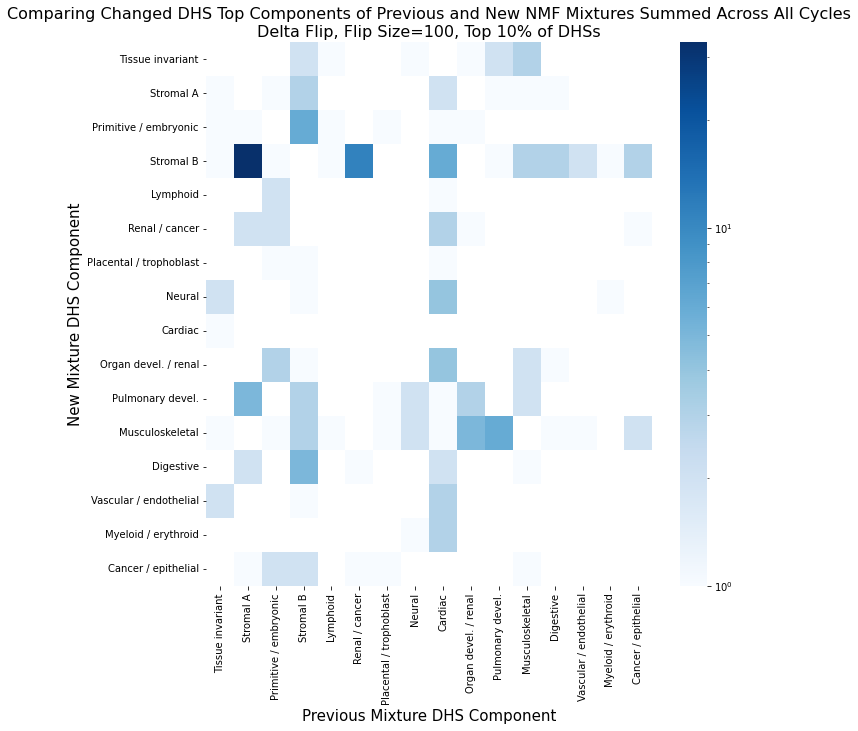

In [22]:
#in plots, yaxis is newest cycle, xaxis is previous cycle
comps_for_heatmap = ['Tissue invariant','Stromal A', 'Primitive / embryonic', 'Stromal B', 'Lymphoid', 'Renal / cancer', 'Placental / trophoblast', 'Neural', 'Cardiac', 'Organ devel. / renal', 'Pulmonary devel.', 'Musculoskeletal', 'Digestive', 'Vascular / endothelial', 'Myeloid / erythroid', 'Cancer / epithelial']

fig = plt.figure(figsize=(10,10))
fig.patch.set_facecolor('white')
ax = sns.heatmap(heatmap_mixture_all_cycles_10per_top_comp_comparison_sum, cmap='Blues', cbar=True, xticklabels=comps_for_heatmap, yticklabels=comps_for_heatmap, norm=LogNorm()) # 
ax.set_ylabel('New Mixture DHS Component', fontsize=15)
ax.set_xlabel('Previous Mixture DHS Component', fontsize=15)
ax.set_title('Comparing Changed DHS Top Components of Previous and New NMF Mixtures Summed Across All Cycles\nDelta Flip, Flip Size=100, Top 10% of DHSs', fontsize=16)

**Measuring DHS mixture purity**

In [11]:
#different options for purity:
#1 top value / average
#2 top value / 2nd largest value
#3 top value / sum

In [66]:
example_mixture = np.array([[0.1, 0.6, 0.1, 0.1], [0, 0, 0.15, 0.5], [0, 0, 0.13, 0.13], [0, 0, 0.11, 0.11]])
example_mixture

array([[0.1 , 0.6 , 0.1 , 0.1 ],
       [0.  , 0.  , 0.15, 0.5 ],
       [0.  , 0.  , 0.13, 0.13],
       [0.  , 0.  , 0.11, 0.11]])

In [69]:
example_mixture_mean

array([0.025 , 0.15  , 0.1225, 0.21  ])

In [67]:
example_mixture_top_comp_val = np.max(example_mixture, axis=0)
example_mixture_mean = np.mean(example_mixture, axis=0)
example_mixture_sum = np.sum(example_mixture, axis=0)
example_mixture_second_top_comp_val = np.array([0, 0, 0.13, 0.13])

example_pur_by_mean = example_mixture_top_comp_val / example_mixture_mean
example_pur_by_sum = example_mixture_top_comp_val / example_mixture_sum
example_pur_by_second_top_comp = example_mixture_top_comp_val / example_mixture_second_top_comp_val

/tmp/ipykernel_16803/3452690410.py:8: RuntimeWarning: divide by zero encountered in true_divide
  example_pur_by_second_top_comp = example_mixture_top_comp_val / example_mixture_second_top_comp_val


In [73]:
print(example_pur_by_mean)
print(example_pur_by_mean/4)
print(example_pur_by_sum) # I like by_sum best
print(example_pur_by_second_top_comp)

[4.         4.         1.2244898  2.38095238]
[1.         1.         0.30612245 0.5952381 ]
[1.         1.         0.30612245 0.5952381 ]
[       inf        inf 1.15384615 3.84615385]


In [23]:
#finding value of top comp
mixture_all_cycles_10per_top_comp_val = np.max(mixture_all_cycles_10per, axis=1)

In [26]:
#finding average of all comps
mixture_all_cycles_10per_mean = np.mean(mixture_all_cycles_10per, axis=1)

In [48]:
#finiding sum of all comps
mixture_all_cycles_10per_sum = np.sum(mixture_all_cycles_10per, axis=1)

In [32]:
#finding second largest value
mixture_all_cycles_10per_second_top_comp_val = []
for i in range(11):
    each_cycle_second_top_comp_val = []
    for dhs in range(len(mixture_all_cycles_10per[i, 0,:])):
        second_largest_ind = np.argsort(mixture_all_cycles_10per[i, :, dhs])[-2]
        each_cycle_second_top_comp_val.append(mixture_all_cycles_10per[i, second_largest_ind, dhs])
    mixture_all_cycles_10per_second_top_comp_val.append(np.array(each_cycle_second_top_comp_val))
mixture_all_cycles_10per_second_top_comp_val = np.array(mixture_all_cycles_10per_second_top_comp_val)

In [54]:
mixture_all_cycles_10per_pur_by_mean = mixture_all_cycles_10per_top_comp_val / mixture_all_cycles_10per_mean
mixture_all_cycles_10per_pur_by_sum = mixture_all_cycles_10per_top_comp_val / mixture_all_cycles_10per_sum
mixture_all_cycles_10per_pur_by_second_top_comp = mixture_all_cycles_10per_top_comp_val / mixture_all_cycles_10per_second_top_comp_val

/tmp/ipykernel_16803/2818663330.py:3: RuntimeWarning: divide by zero encountered in true_divide
  mixture_all_cycles_10per_pur_by_second_top_comp = mixture_all_cycles_10per_top_comp_val / mixture_all_cycles_10per_second_top_comp_val


In [242]:
#all DHSs
mixture_all_cycles_top_comp_val = np.max(mixture_all_cycles, axis=1)
mixture_all_cycles_sum = np.sum(mixture_all_cycles, axis=1)

mixture_all_cycles_pur_by_sum = mixture_all_cycles_top_comp_val / mixture_all_cycles_sum

In [243]:
pur_diff_10per_tot_between_cycles = []

for i in range(1, 11):
    pur_diff = mixture_all_cycles_10per_pur_by_sum[i, :] - mixture_all_cycles_10per_pur_by_sum[0, :]
    pur_diff_10per_tot_between_cycles.append(pur_diff)
    
pur_diff_10per_tot_between_cycles = np.array(pur_diff_10per_tot_between_cycles)

In [244]:
pur_diff_tot_between_cycles = []

for i in range(1, 11):
    pur_diff = mixture_all_cycles_pur_by_sum[i, :] - mixture_all_cycles_pur_by_sum[0, :]
    pur_diff_tot_between_cycles.append(pur_diff)
    
pur_diff_tot_between_cycles = np.array(pur_diff_tot_between_cycles)

In [278]:
for i in mixture_all_cycles_10per_pur_by_sum:
    print(np.mean(i))

0.5071798
0.5071265
0.50712806
0.5071299
0.5071312
0.5071335
0.50713515
0.5071368
0.50713813
0.5071394
0.50714105


In [228]:
# changed_dhss_all_cycles_combined = []
# for i in changed_dhss_all_cycles:
#     changed_dhss_all_cycles_combined.extend(i)
# changed_dhss_all_cycles_combined = np.unique(changed_dhss_all_cycles_combined)

Text(0.5, 1.0, 'Comparing Change in Purity of NMF Mixture for Each Cycle to Original\nDelta Flip, Flip Size=100, DHSs with Added Call (Previously 0)')

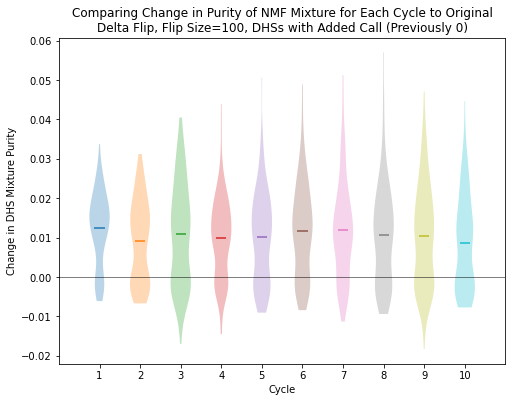

In [265]:
fig = plt.figure(figsize=(8,6))
fig.patch.set_facecolor('white')

plt.plot([-1, 12], [0, 0], color='k', linewidth=0.5)
for i in range(10):
    plt.violinplot(pur_diff_tot_between_cycles[i, np.unique(filtered_DHS_inds_all_cycles[i])], positions=[i+1], showextrema=False, showmeans=True, points=500)#

# plt.yscale('log')
plt.xlim([0, 11])
# plt.ylim([-0.001, 0.001])
# plt.ylim([-0.005, 0.005])
plt.xticks(np.arange(1, 11))
    
# plt.legend(['Increase in Purity', 'Decrease in Purity', 'No Change in Purity'])

plt.xlabel('Cycle')
plt.ylabel('Change in DHS Mixture Purity')
plt.title('Comparing Change in Purity of NMF Mixture for Each Cycle to Original\nDelta Flip, Flip Size=100, DHSs with Added Call (Previously 0)')

**Basis purity**

In [270]:
basis_all_cycles_top_comp_val = np.max(basis_all_cycles, axis=2)
basis_all_cycles_sum = np.sum(basis_all_cycles, axis=2)

basis_all_cycles_pur_by_sum = basis_all_cycles_top_comp_val / basis_all_cycles_sum

In [272]:
basis_pur_diff_tot_between_cycles = []

for i in range(1, 11):
    pur_diff = basis_all_cycles_pur_by_sum[i, :] - basis_all_cycles_pur_by_sum[0, :]
    basis_pur_diff_tot_between_cycles.append(pur_diff)
    
basis_pur_diff_tot_between_cycles = np.array(basis_pur_diff_tot_between_cycles)

Text(0.5, 1.0, 'Comparing Change in Purity of NMF Basis for Each Cycle to Original\nDelta Flip, Flip Size=100, Biosamples with Added Call (Previously 0)')

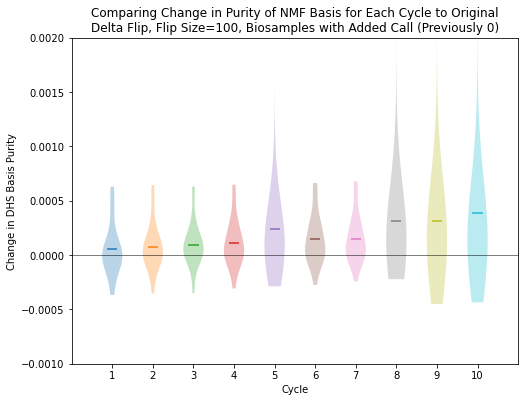

In [279]:
fig = plt.figure(figsize=(8,6))
fig.patch.set_facecolor('white')

plt.plot([-1, 12], [0, 0], color='k', linewidth=0.5)
for i in range(10):
    plt.violinplot(basis_pur_diff_tot_between_cycles[i, np.unique(filtered_biosample_inds_all_cycles[i])], positions=[i+1], showextrema=False, showmeans=True, points=500)#

# plt.yscale('log')
plt.xlim([0, 11])
plt.ylim([-0.001, 0.002])
# plt.ylim([-0.005, 0.005])
plt.xticks(np.arange(1, 11))
    
# plt.legend(['Increase in Purity', 'Decrease in Purity', 'No Change in Purity'])

plt.xlabel('Cycle')
plt.ylabel('Change in DHS Basis Purity')
plt.title('Comparing Change in Purity of NMF Basis for Each Cycle to Original\nDelta Flip, Flip Size=100, Biosamples with Added Call (Previously 0)')

**Number of samples vs NMF Mixture Loadings**

In [32]:
cycle_1_mixture_top_10_percent_filtered = cycle_1_mixture_top_10_percent[:, cycle_1_mixture_top_10_percent_not_all_0_inds]
cycle_2_mixture_top_10_percent_filtered = cycle_2_mixture_top_10_percent[:, cycle_2_mixture_top_10_percent_not_all_0_inds]
cycle_3_mixture_top_10_percent_filtered = cycle_3_mixture_top_10_percent[:, cycle_3_mixture_top_10_percent_not_all_0_inds]

#finiding sum of all comps
cycle_0_mixture_top_10_percent_sum = np.sum(cycle_0_mixture_top_10_percent, axis=0)
cycle_1_mixture_top_10_percent_filtered_sum = np.sum(cycle_1_mixture_top_10_percent_filtered, axis=0)
cycle_2_mixture_top_10_percent_filtered_sum = np.sum(cycle_2_mixture_top_10_percent_filtered, axis=0)
cycle_3_mixture_top_10_percent_filtered_sum = np.sum(cycle_3_mixture_top_10_percent_filtered, axis=0)

In [37]:
#top 10% of dhss
dhs_array_top_10_percent = dhs_array[:, top_10_percent_DHSs_inds]
updated_dhs_array_all_delta_0001_1_cycle_top_10_percent_filtered = updated_dhs_array_all_delta_0001_1_cycle[:, top_10_percent_DHSs_inds]
updated_dhs_array_all_delta_0001_2_cycles_top_10_percent_filtered = updated_dhs_array_all_delta_0001_2_cycles[:, top_10_percent_DHSs_inds]
updated_dhs_array_all_delta_0001_3_cycles_top_10_percent_filtered = updated_dhs_array_all_delta_0001_3_cycles[:, top_10_percent_DHSs_inds]
#filtering these DHS arrays such that we are only looking at DHSs with biosample representation
updated_dhs_array_all_delta_0001_1_cycle_top_10_percent_filtered = updated_dhs_array_all_delta_0001_1_cycle_top_10_percent_filtered[:, cycle_1_mixture_top_10_percent_not_all_0_inds]
updated_dhs_array_all_delta_0001_2_cycles_top_10_percent_filtered = updated_dhs_array_all_delta_0001_2_cycles_top_10_percent_filtered[:, cycle_2_mixture_top_10_percent_not_all_0_inds]
updated_dhs_array_all_delta_0001_3_cycles_top_10_percent_filtered = updated_dhs_array_all_delta_0001_3_cycles_top_10_percent_filtered[:, cycle_3_mixture_top_10_percent_not_all_0_inds]

In [40]:
dhs_array_top_10_percent_numsamples = np.sum(dhs_array_top_10_percent, axis=0)
updated_dhs_array_all_delta_0001_1_cycle_top_10_percent_filtered_numsamples = np.sum(updated_dhs_array_all_delta_0001_1_cycle_top_10_percent_filtered, axis=0)
updated_dhs_array_all_delta_0001_2_cycles_top_10_percent_filtered_numsamples = np.sum(updated_dhs_array_all_delta_0001_2_cycles_top_10_percent_filtered, axis=0)
updated_dhs_array_all_delta_0001_3_cycles_top_10_percent_filtered_numsamples = np.sum(updated_dhs_array_all_delta_0001_3_cycles_top_10_percent_filtered, axis=0)

Text(0.5, 1.0, 'Comparing Number of Samples to Sum of NMF Mixture Loading\nDelta Fill-in, Fill Size=0.01%')

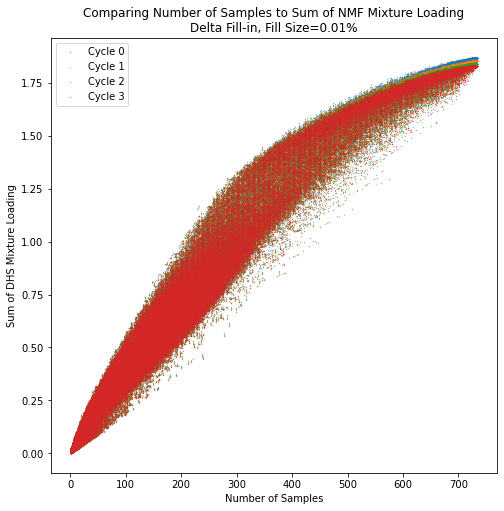

In [61]:
fig = plt.figure(figsize=(8,8))
fig.patch.set_facecolor('white')

plt.scatter(dhs_array_top_10_percent_numsamples, cycle_0_mixture_top_10_percent_sum, s=0.1, alpha=0.8)
plt.scatter(updated_dhs_array_all_delta_0001_1_cycle_top_10_percent_filtered_numsamples, cycle_1_mixture_top_10_percent_filtered_sum, s=0.1, alpha=0.8)
plt.scatter(updated_dhs_array_all_delta_0001_2_cycles_top_10_percent_filtered_numsamples, cycle_2_mixture_top_10_percent_filtered_sum, s=0.1, alpha=0.8)
plt.scatter(updated_dhs_array_all_delta_0001_3_cycles_top_10_percent_filtered_numsamples, cycle_3_mixture_top_10_percent_filtered_sum, s=0.1, alpha=0.8)


plt.legend(['Cycle 0', 'Cycle 1', 'Cycle 2', 'Cycle 3'])
plt.xlabel('Number of Samples')
plt.ylabel('Sum of DHS Mixture Loading')
plt.title('Comparing Number of Samples to Sum of NMF Mixture Loading\nDelta Fill-in, Fill Size=0.01%')